# ParFlow Short Course: Overland Flow
## Exercise: Rainfall Runoff Hydrograph on a Tilted-V

### Goal
The goal of this exercise is to understand the basic principle of runff generation by the process of excess infiltration (i.e. when the rain rate exceeds the saturated hydraulic conductivity of the surface). In addition, three different top boundary conditions are introduced that simulate overland flow based on different assumptions applied to the shallow water approximation (e.g. kinematic versus diffusive). 

### Domain Description
Refer to the figure below for details on the domain setup. 

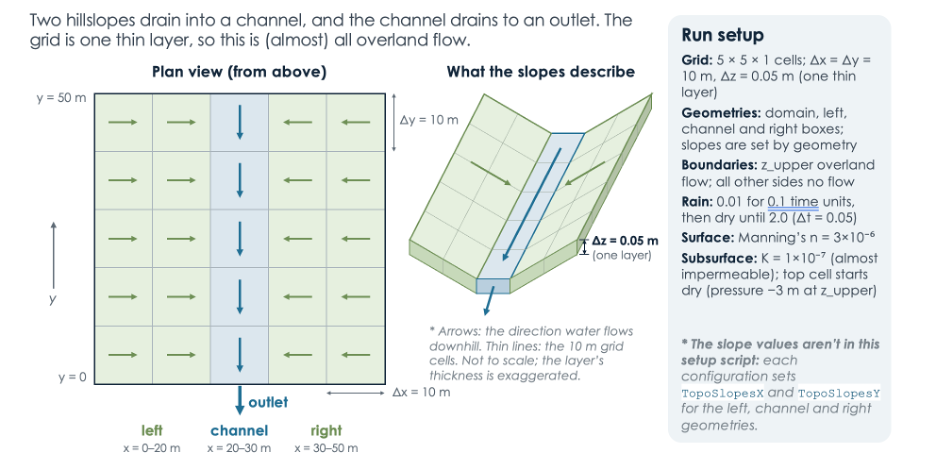

## 0. Import the required packages


In [ ]:
# Import the ParFlow package
from parflow import Run
import os
import sys
from parflow.tools.fs import mkdir, cp, chdir, get_absolute_path, rm, exists
import parflow.tools.hydrology as hydro
import numpy as np
import matplotlib.pyplot as plt
from parflow.tools.io import read_pfb
from glob import glob

# Import functions for plotting
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../utils")))
from plots import plot_domain_overland, plot_streamflow

#Name used for the pfidb that contains the baseline run information
baseline_setup_name = "overland_tiltedV"


## Part 1: Illustrating different geometric configurations. 
This sections shows how to configure the tilted V for either the `OverlandFlow` or `OverlandKinematic` boundary conditions. 

Experiment yourself for either approcah with: 
1. Change the slope of the channel and the hillslopes
1. Turn the V so the streamflow flows out the north end of the domain instead of the south (This will also require to change the outlet point in order to plot the streamflow)
1. BONUS challenge: Turn the V 90 degrees. 


### 1.1 OverlandFlow formulation
Setting slopes consistent with the cell centered appraoch for the OverlandFlow boundary condition

In [ ]:
# Import run information from pfidb
overland = Run.from_definition(f"{baseline_setup_name}.pfidb")
new_name = 'OF_BC' #This is the name you want to save your new run as
overland.set_name(new_name)


#-----------------------------------------------------------------------------
# Tilted-V Formulation 1
# Original formulation with a zero value channel
#-----------------------------------------------------------------------------
overland.TopoSlopesX.Type = 'Constant'
overland.TopoSlopesX.GeomNames = 'left right channel'
overland.TopoSlopesX.Geom.left.Value = -0.01
overland.TopoSlopesX.Geom.right.Value = 0.01
overland.TopoSlopesX.Geom.channel.Value = 0.00

overland.TopoSlopesY.Type = 'Constant'
overland.TopoSlopesY.GeomNames = 'domain'
overland.TopoSlopesY.Geom.domain.Value = 0.01

# original approach from K&M AWR 2006
overland.Patch.z_upper.BCPressure.Type = 'OverlandFlow'
overland.Solver.Nonlinear.UseJacobian = True
overland.Solver.Linear.Preconditioner.PCMatrixType = 'PFSymmetric'

# run the model 
base = os.path.join(os.getcwd(), "tiltedV_runs", overland.get_name())
mkdir(base)
print(f"base: {base}")
overland.run(working_directory=base)

base: /workspaces/ParFlow_CUAHSI_VU/my_work/tiltedV_runs/OF_BC
: Field _run_file is not part of the expected schema <class 'parflow.tools.core.Run'>

# ==============================================================================
# ParFlow directory
#  - /opt/parflow/
# ParFlow version
#  - 3.15.0
# Working directory
#  - /workspaces/ParFlow_CUAHSI_VU/my_work/tiltedV_runs/OF_BC
# ParFlow database
#  - OF_BC.pfidb
# ==============================================================================


# ==============================================================================
# ParFlow ran successfully
# ==============================================================================



### 1.2 OverlandKinematic Formulation
Modifying the slopes so that they are face centered and applying the OverlandKinematic Boundary Condition instead

In [6]:
# Import run information from pfidb
overland = Run.from_definition(f"{baseline_setup_name}.pfidb")
new_name = 'OKIN_BC' #This is the name you want to save your new run as
overland.set_name(new_name)

#-----------------------------------------------------------------------------
# Tilted-V Formulation 2
# New kinematic formulations without the zero channel
# Note: The difference in configuration here is to be consistent with the way
#   the upwinding is handled for the new and original fomulations.
#   These two results should be almost identical for the new and old formulations
#-----------------------------------------------------------------------------
overland.TopoSlopesX.Type = 'Constant'
overland.TopoSlopesX.GeomNames = 'left right channel'
overland.TopoSlopesX.Geom.left.Value = -0.01
overland.TopoSlopesX.Geom.right.Value = 0.01
overland.TopoSlopesX.Geom.channel.Value = 0.01

overland.TopoSlopesY.Type = 'Constant'
overland.TopoSlopesY.GeomNames = 'domain'
overland.TopoSlopesY.Geom.domain.Value = 0.01

# run with KWE upwinding
overland.Patch.z_upper.BCPressure.Type = 'OverlandKinematic'
overland.Solver.Nonlinear.UseJacobian = True
overland.Solver.Linear.Preconditioner.PCMatrixType = 'PFSymmetric'

# run the model 
base = os.path.join(os.getcwd(), "tiltedV_runs", overland.get_name())
mkdir(base)
print(f"base: {base}")
overland.run(working_directory=base)

base: /workspaces/ParFlow_CUAHSI_VU/my_work/tiltedV_runs/OKIN_BC
: Field _run_file is not part of the expected schema <class 'parflow.tools.core.Run'>

# ==============================================================================
# ParFlow directory
#  - /opt/parflow/
# ParFlow version
#  - 3.15.0
# Working directory
#  - /workspaces/ParFlow_CUAHSI_VU/my_work/tiltedV_runs/OKIN_BC
# ParFlow database
#  - OKIN_BC.pfidb
# ==============================================================================


# ==============================================================================
# ParFlow ran successfully
# ==============================================================================



## Part 2: Experiment with overland flow
Use the code block below as a starting point to experiment with: 
1. Changing the mannings roughness coefficient
1. Add a second rainstorm by decreasing the recession length
1. Changing the permeability or thickness of the domain

**Remember** 
- If you want to do multiple runs you shoud save them with different names so your results don't get overwritten. 
- Don't keep too many simulations on your code space at once or it will get bogged down. You can also increase the dump interval or decrease the length of your simulation to manage the amount of outputs you are storing. 


In [ ]:
# Import run information from pfidb
overland = Run.from_definition(f"{baseline_setup_name}.pfidb")
new_name = 'Test1' #This is the name you want to save your new run as
overland.set_name(new_name)

#_______
# Set whatever keys you need to in here. Refer back to the baseline run setup for keys that are available to change


#____


# run the model 
base = os.path.join(os.getcwd(), "tiltedV_runs", overland.get_name())
mkdir(base)
print(f"base: {base}")
overland.run(working_directory=base)


## Part 3: Plotting

Use the blocks of code below to plot outputs.

### 3.1 Compare outflow time series from multiple simulations

Set `run_names` to the simulation names under `tiltedV_runs`. Outflow is calculated from each run's pressure, slope, and Manning's output using `hydro.calculate_overland_flow`.

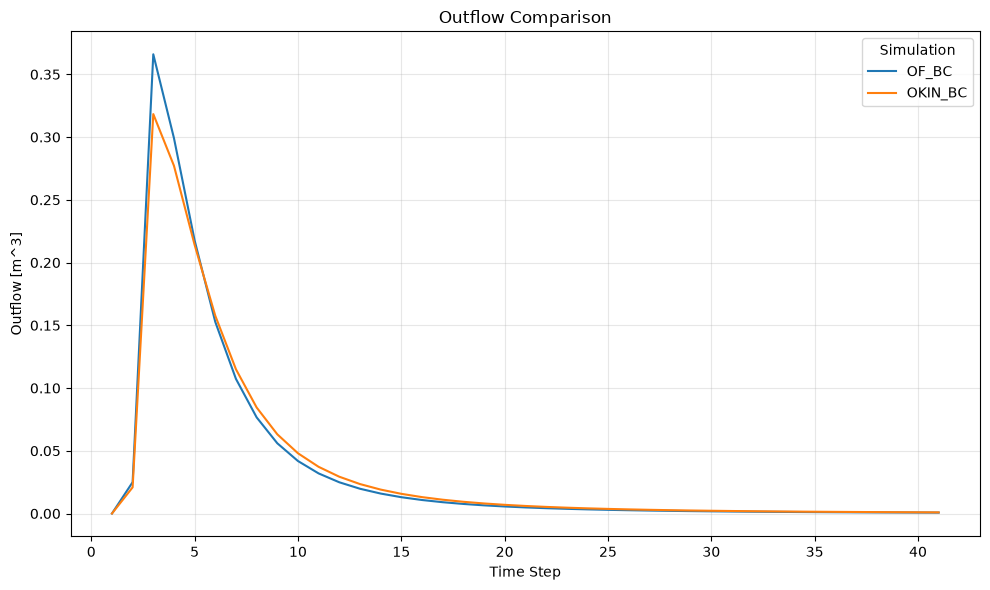

In [10]:
# Add or remove simulation names to compare their outflow time series.
run_names = ["OF_BC", "OKIN_BC"]

if not run_names:
    raise ValueError("Add at least one run name to run_names.")


fig, ax = plt.subplots(figsize=(10, 6))

for run_name in run_names:
    run_dir = os.path.join(os.getcwd(), "tiltedV_runs", run_name)
    pressure_files = sorted(glob(os.path.join(run_dir, f"{run_name}.out.press.*.pfb")))
    if not pressure_files:
        raise FileNotFoundError(
            f"No pressure output files found for run {run_name!r} in {run_dir}"
        )

    run = Run.from_definition(os.path.join(run_dir, f"{run_name}.pfidb"))
    data = run.data_accessor
    dx, dy = data.dx, data.dy
    dt = run.TimeStep.Value
    mask = data.mask
    slopex = data.slope_x.squeeze()
    slopey = data.slope_y.squeeze()
    mannings = data.mannings.squeeze()

    keys = run.to_dict()
    flow_method = keys.get("Patch.z_upper.BCPressure.Type", "OverlandFlow")

    overland_out = np.zeros(len(pressure_files))
    for t, pressure_file in enumerate(pressure_files):
        pressure = read_pfb(pressure_file)
        overland_out[t] = hydro.calculate_overland_flow(
            pressure,
            slopex,
            slopey,
            mannings,
            dx,
            dy,
            flow_method=flow_method,
            mask=mask,
        )

    outflow = overland_out * dt
    time_steps = np.arange(1, len(outflow) + 1)
    ax.plot(time_steps, outflow, label=run_name)

ax.set_title("Outflow Comparison")
ax.set_xlabel("Time Step")
ax.set_ylabel("Outflow [m^3]")
ax.legend(title="Simulation")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


### 3.2 Compare pressure fields across simulations

Choose a saved timestep and simulation names. The panels use the uppermost model layer and share a color scale for comparison.

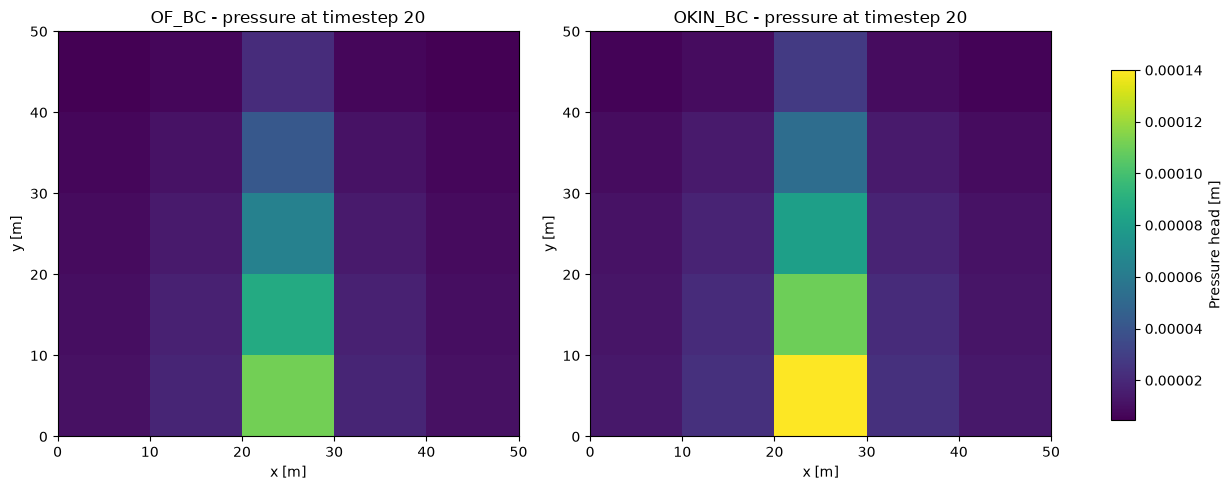

In [11]:
# Choose the saved timestep and simulations to compare.
pressure_timestep = 20
pressure_run_names = ["OF_BC", "OKIN_BC"]


if not pressure_run_names:
    raise ValueError("Add at least one run name to pressure_run_names.")
if pressure_timestep < 0:
    raise ValueError("pressure_timestep must be zero or greater.")

fig, axes = plt.subplots(
    nrows=(len(pressure_run_names) + 1) // 2,
    ncols=2,
    figsize=(12, 5 * ((len(pressure_run_names) + 1) // 2)),
    squeeze=False,
)
pressure_fields = []
field_extents = []

for run_name in pressure_run_names:
    run_dir = os.path.join(os.getcwd(), "tiltedV_runs", run_name)
    pressure_file = os.path.join(
        run_dir, f"{run_name}.out.press.{pressure_timestep:05d}.pfb"
    )
    if not os.path.isfile(pressure_file):
        raise FileNotFoundError(
            f"Pressure output for timestep {pressure_timestep} not found for "
            f"run {run_name!r}: {pressure_file}"
        )

    run = Run.from_definition(os.path.join(run_dir, f"{run_name}.pfidb"))
    data = run.data_accessor
    pressure = read_pfb(pressure_file)
    pressure_fields.append((run_name, pressure[-1, :, :]))
    field_extents.append(
        (0, pressure.shape[2] * data.dx, 0, pressure.shape[1] * data.dy)
    )

vmin = min(np.nanmin(field) for _, field in pressure_fields)
vmax = max(np.nanmax(field) for _, field in pressure_fields)
image = None
for i, ((run_name, field), extent) in enumerate(zip(pressure_fields, field_extents)):
    ax = axes.flat[i]
    image = ax.imshow(
        field,
        origin="lower",
        extent=extent,
        aspect="auto",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_title(f"{run_name} - pressure at timestep {pressure_timestep}")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")

for ax in axes.flat[len(pressure_run_names):]:
    ax.set_visible(False)

fig.tight_layout(rect=[0, 0, 0.9, 1])
colorbar_ax = fig.add_axes([0.93, 0.15, 0.02, 0.7])
fig.colorbar(image, cax=colorbar_ax, label="Pressure head [m]")
plt.show()
